# 02 SPICE on the board netlist (tier C, board mode)

[![Open In Colab](https://colab.research.google.com/assets/colab/badge.svg)](https://colab.research.google.com/github/<owner>/dlnn-paper/blob/main/notebooks/02_spice_board.ipynb)

**What this notebook does.** It runs **ngspice** on the KiCad-exported netlists of the three TILE-8 boards (`hw/board/tile/layer{1,2,3}/tile.cir`; the board is *designed, not built*, nothing here is measured):

1. `.ac` of every tap (the 56-section LC ladder, input RC, tap buffers) and `.dc` of the bias -> summer -> BJT diff pair -> diff amp -> track-and-hold chain, for the Q = 10 and Q = 30 inductor corners;
2. dumps the browser data the article's SPICE widget reads (`docs/artifacts/data/spice/*.json`, `unit_cell.template.cir`, `manifest.json`);
3. a **whole-tile `.tran`** of the 3-layer chain on a few test examples (small n: about 20 s per example) and its comparison with the circuit-calibrated behavioural model;
4. the **behavioural C tier** on the full 4000-example test set (this one is *not* SPICE; it is a model fitted to the SPICE results above) and its comparison with the stored full run.

The netlists are the committed exports of `hw/board/gen_tile.py --model models/tdlnet_b_w8_aware2_fro_ternary.npz` + `kicad-cli`. KiCad is not needed to run this notebook; the netlist hashes are checked against `docs/artifacts/data/spice/manifest.json`. All parts are generic or datasheet-derived lumped models (no proprietary op-amp macro): inductor = L + DCR + Cp + Rp(Q), op-amp = single-pole fit, NPN = generic BC847-fitted, 4066 = Ron + Coff. No layout parasitics, crosstalk or noise here (that is the P tier, notebook 03).

In [1]:
# Colab only: install the system tools, clone the repo, install the pinned Python requirements. Skipped everywhere else.
import sys
if 'google.colab' in sys.modules:
    import os, subprocess
    REPO_URL = "https://github.com/<owner>/dlnn-paper"      # TODO: replace with the real URL once the repo is public
    subprocess.run("apt-get -qq install -y ngspice iverilog", shell=True, check=True)
    if not os.path.isdir("/content/dlnn-paper"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/dlnn-paper"], check=True)
    os.chdir("/content/dlnn-paper")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

In [2]:
import os, sys, time, json
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists() and (p / "dlnn").is_dir())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # run from the repo root so relative paths in the library resolve
import numpy as np
from dlnn import paper
from dlnn.paper import DATA, EXPECTED, WORK
T0 = time.time()
ENV = paper.banner("02 SPICE on the board netlist")

02 SPICE on the board netlist
  python: 3.12.3
  numpy: 2.5.4
  platform: Linux-6.18.44-fc-v233-x86_64-with-glibc2.39
  ngspice: ngspice-42 : Circuit level simulation program
  iverilog: Icarus Verilog version 12.0 (stable) ()
  node: v22.23.4
  colab: False
  Simulation of a design that is not built. Nothing here is a measurement.


In [3]:
import shutil
assert shutil.which("ngspice"), "ngspice not found (Colab: apt-get install ngspice; Debian/Ubuntu: apt install ngspice)"
from dlnn.data import modrec
from dlnn.model.npz import load_model
from dlnn.tiers import circuit_board as cb, circuit, virtual
MODEL = "models/tdlnet_b_w8_aware2_fro_ternary.npz"
model = load_model(MODEL)
ds = modrec.dataset()
REF = paper.read_json("models/board_aware/c_board_aware2_fro_ref.json")      # stored operating point + numbers of the full SPICE run
MAN = paper.read_json(EXPECTED / "data" / "spice" / "manifest.json")
print("ngspice:", circuit.ngspice_version())
print("model file sha256", paper.sha256_file(MODEL)[:16], "(expected", MAN["model_file_sha256"][:16] + ")")
assert paper.sha256_file(MODEL) == MAN["model_file_sha256"]

ngspice: 42
model file sha256 3405923d2c64bb0c (expected 3405923d2c64bb0c)


## 1. The exported netlists

Three tiles: layer 1 has 2 of 8 lines populated, layers 2 and 3 are full (8 lines x 56 LC sections = 448 inductors).

In [4]:
info = cb.info_from_netlists(MODEL)
rows = []
for L in ("1", "2", "3"):
    cir = Path(info["layers"][L]["cir"])
    txt = cir.read_text()
    n_ind = sum(1 for l in txt.splitlines() if l.startswith("XL") and "IND_FH1812" in l)
    rows.append({"tile": f"layer {L}", "netlist lines": txt.count("\n"), "inductors (XL*)": n_ind, "sha256_16": info["layers"][L]["cir_sha256"][:16],
                 "matches manifest": info["layers"][L]["cir_sha256"] == MAN["tile_cir_sha256"][L]})
import pandas as pd; print(pd.DataFrame(rows).to_string(index=False))
assert all(r["matches manifest"] for r in rows)

   tile  netlist lines  inductors (XL*)        sha256_16  matches manifest
layer 1            510              112 105317990030d011              True
layer 2           1482              448 90db34ea57cad85f              True
layer 3           1483              448 31ea8ecdbf6a46a5              True


## 2. `.ac` and `.dc` per tile, both inductor corners

`calibrate` runs, per tile: `.ac` of the 8 taps (FIR at symbol rate, clock and sampling phase), `.dc` of the amplifier chain (per-channel tanh fit, bias-DAC trim). Q = 10 is the datasheet minimum; Q = 30 is an *assumed* typical value.

In [5]:
t = time.time()
WB = WORK / "spice_board"
RF_SCALE = REF["eco"]["rf_rb_ro_scale"]        # ECO-2 of the stored run: R_f, R_b, R_o x 2.9 (tap-gain restoration for the M1a-FIR board net); ECO-1: line termination to mid-rail
cal = {q: cb.calibrate(MODEL, WB, q=q, info=info, rf_scale=RF_SCALE) for q in (10.0, 30.0)}
print(f"calibrate Q10 + Q30: {time.time() - t:.1f} s")
for q, c in cal.items():
    print(f"Q{int(q)}: T = {c['summary'][0]['T_s']*1e6:.3f} us, t0 = {[round(s['t0_s']*1e9) for s in c['summary']]} ns, "
          f"tanh fit R^2 min = {min(f['r2'] for s in c['summary'] for f in s['amp_fit']):.4f}, DAC-clipped channels {[s['clipped_channels'] for s in c['summary']]}")

calibrate Q10 + Q30: 2.6 s
Q10: T = 0.946 us, t0 = [1115, 1115, 1115] ns, tanh fit R^2 min = 1.0000, DAC-clipped channels [0, 0, 0]
Q30: T = 0.947 us, t0 = [1131, 1131, 1131] ns, tanh fit R^2 min = 1.0000, DAC-clipped channels [0, 0, 0]


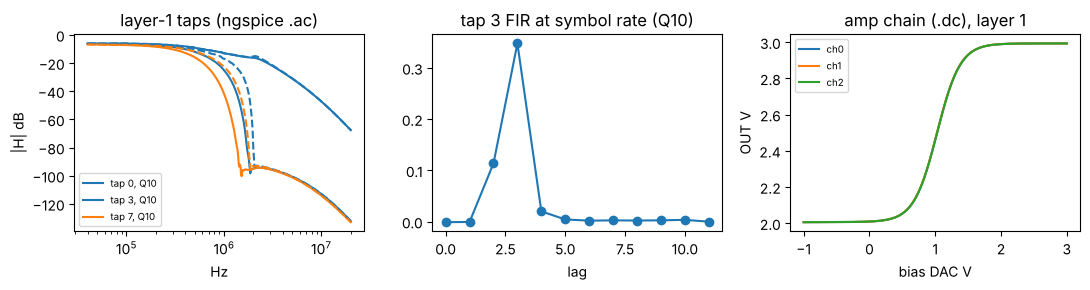

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for q, c in cal.items():
    su = c["setups"][0]
    f = su.ac["freq_hz"]
    for k in (0, 3, 7):
        ax[0].semilogx(f[1:], 20 * np.log10(np.abs(su.ac["H"][k][1:])), label=f"tap {k}, Q{int(q)}" if q == 10 else None, ls="-" if q == 10 else "--", color=f"C{k % 3}")
ax[0].set_xlabel("Hz"); ax[0].set_ylabel("|H| dB"); ax[0].set_title("layer-1 taps (ngspice .ac)"); ax[0].legend(fontsize=7)
s10 = cal[10.0]["setups"][0]
ax[1].plot(s10.fir[3], "o-"); ax[1].set_title("tap 3 FIR at symbol rate (Q10)"); ax[1].set_xlabel("lag")
d = s10.dc
for o in range(3):
    ax[2].plot(d["vsw"], d["out"][o], label=f"ch{o}")
ax[2].set_xlabel("bias DAC V"); ax[2].set_ylabel("OUT V"); ax[2].set_title("amp chain (.dc), layer 1"); ax[2].legend(fontsize=7)
fig.tight_layout()

## 3. Browser data for the article's SPICE widget

`export_web` writes `unit_cell.template.cir`, `tap_response.json`, `diffpair_dc.json` and `manifest.json` into `docs/artifacts/data/spice/` (same files the article reads). `tap_response.json` and `diffpair_dc.json` are compared byte for byte with the reference snapshot; the numbers can differ in the last digits on an older ngspice (the comparison below also reports the numeric difference).

In [7]:
t = time.time()
SPICE_OUT = DATA / "spice"
man = cb.export_web(SPICE_OUT, MODEL, run_id=MAN["run_id"], rf_scale=RF_SCALE, info=info)
shutil.rmtree(SPICE_OUT / "_work", ignore_errors=True)
print(f"export_web: {time.time() - t:.1f} s")
rows = []
for name in ("tap_response.json", "diffpair_dc.json", "unit_cell.template.cir"):
    new, ref = SPICE_OUT / name, EXPECTED / "data" / "spice" / name
    rows.append({"file": name, "bytes": new.stat().st_size, "identical": paper.sha256_file(new) == paper.sha256_file(ref)})
print(pd.DataFrame(rows).to_string(index=False))
a, b = paper.read_json(SPICE_OUT / "tap_response.json"), paper.read_json(EXPECTED / "data/spice/tap_response.json")
def maxdiff(x, y):
    if isinstance(x, dict):
        return max([maxdiff(x[k], y[k]) for k in x if k in y] + [0.0])
    if isinstance(x, list):
        return max([maxdiff(i, j) for i, j in zip(x, y)] + [0.0])
    if isinstance(x, (int, float)) and isinstance(y, (int, float)):
        return abs(x - y)
    return 0.0
d_tap = maxdiff(a, b); d_dc = maxdiff(paper.read_json(SPICE_OUT / "diffpair_dc.json"), paper.read_json(EXPECTED / "data/spice/diffpair_dc.json"))
print(f"max |new - reference|: tap_response {d_tap:.3g}, diffpair_dc {d_dc:.3g}")
assert d_tap < 1e-3 and d_dc < 1e-3

export_web: 1.9 s
                  file  bytes  identical
     tap_response.json  33237       True
      diffpair_dc.json   2467       True
unit_cell.template.cir   6810       True
max |new - reference|: tap_response 0, diffpair_dc 0


## 4. Whole-tile `.tran`, small n

The full SPICE transient of the three-layer chain (8 lines x 56 LC sections, 64 tap buffers, 1024 crossbar footprints, summers, pairs, S/H per layer; layer 2 is driven by layer 1's S/H samples, layer 3 by layer 2's). It uses the stored operating point of the full run (symbol period, sampling phase, post-chain fit, `models/board_aware/c_board_aware2_fro_ref.json`). The full run used 64 examples; here only a few, so the layer-wise NMSE of the calibrated model against SPICE is compared with the stored 64-example numbers at a wider tolerance.

In [8]:
N_TRAN = int(os.environ.get("DLNN_TRAN_N", 3))
def apply_operating_point(setups, qn):
    c = REF["corners"][qn]
    for s_, pf in zip(setups, c["post_fit"]["layers"]):
        s_.tau_post, s_.e_fit = pf["tau_post_s"], pf["e_sh"]
        s_.set_clock(c["operating_point"]["T_us"] * 1e-6, c["operating_point"]["t0_eff_us"] * 1e-6)
    return setups
su10 = apply_operating_point(cal[10.0]["setups"], "Q10")
idx = np.array(REF["test_subset_idx"][::max(1, 64 // N_TRAN)][:N_TRAN])        # examples of the stored 64-example subset, spread over classes/SNRs
X = ds["x_test"][idx]
t = time.time()
sp = cb.run_spice(su10, model, X, WB / "tran", tag="nb")
t_tran = time.time() - t
print(f"SPICE .tran of {N_TRAN} examples x 3 layers: {t_tran:.0f} s ({t_tran / N_TRAN:.0f} s per example); node voltage range {sp['out_min_v']:.2f} .. {sp['out_max_v']:.2f} V (rails 0..5 V)")
calf = cb.cal_forward(model, cb.cal_models(su10), X)
nm = [cb.nmse(calf["layers"][l], sp["y"][l]) for l in range(3)]
ref_nm = REF["corners"]["Q10"]["calibrated_chain_vs_spice_chain_nmse"]
rows = []
for l in range(3):
    paper.check(rows, f"layer {l + 1}: NMSE(calibrated model, SPICE chain)", nm[l], ref_nm[l], max(0.1, 3 * ref_nm[l]), note=f"stored 64-ex value {ref_nm[l]:.4f}, here n={N_TRAN}")
o_sp = cb.readout_from_samples(model, sp["y"]); o_cal = calf["out"]; o_v = virtual.forward(model, X)["out"]
print("true", ds["y_test"][idx], "| SPICE", o_sp.argmax(1), "| calibrated", o_cal.argmax(1), "| ideal V", o_v.argmax(1))
spice_tran = paper.show_rows(rows)

SPICE .tran of 3 examples x 3 layers: 60 s (20 s per example); node voltage range 1.01 .. 3.01 V (rails 0..5 V)
true [0 4 0] | SPICE [0 1 0] | calibrated [0 1 0] | ideal V [0 0 0]
                                       check       got  reference      tol unit result                                note
layer 1: NMSE(calibrated model, SPICE chain) 0.0281104  0.0157233      0.1        PASS stored 64-ex value 0.0157, here n=3
layer 2: NMSE(calibrated model, SPICE chain) 0.0737848  0.0416115 0.124834        PASS stored 64-ex value 0.0416, here n=3
layer 3: NMSE(calibrated model, SPICE chain)  0.200488   0.157096 0.471287        PASS stored 64-ex value 0.1571, here n=3


## 5. Behavioural C tier on the full test set

The numbers the article quotes for C in board mode come from this model (fitted to the SPICE results of section 2 and to calibration transients), **not** from SPICE. For Q = 30 the stored operating point of the full run is used as well.

In [9]:
t = time.time()
su30 = apply_operating_point(cal[30.0]["setups"], "Q30")
res = {}
rows = []
for qn, su in (("Q10", su10), ("Q30", su30)):
    out = cb.cal_forward(model, cb.cal_models(su), ds["x_test"])["out"]
    res[qn] = cb.acc(out, ds["y_test"])
    paper.check(rows, f"C board (behavioural), full 4000, {qn}", res[qn], REF["corners"][qn]["full4000"]["acc_C_calibrated"], 0.01, "fraction", note="stored run also fitted a post-chain low-pass (not stored); older ngspice shifts digits")
v_ideal = cb.acc(virtual.forward(model, ds["x_test"])["out"], ds["y_test"])
paper.check(rows, "V ideal, full 4000", v_ideal, REF["V_ideal_accuracy_4000"], 0.0005, "fraction")
print(f"{time.time() - t:.1f} s")
c_rows = paper.show_rows(rows)
assert all(r["result"] == "PASS" for r in rows + spice_tran.to_dict("records"))

5.8 s
                                check     got  reference    tol     unit result                                                                                   note
C board (behavioural), full 4000, Q10  0.8535     0.8565   0.01 fraction   PASS stored run also fitted a post-chain low-pass (not stored); older ngspice shifts digits
C board (behavioural), full 4000, Q30 0.86025    0.86225   0.01 fraction   PASS stored run also fitted a post-chain low-pass (not stored); older ngspice shifts digits
                   V ideal, full 4000   0.655      0.655 0.0005 fraction   PASS                                                                                       


In [10]:
paper.write_json(DATA / "spice" / "tile_tran.json", {
    "schema": "dlnn-c-board-nb/1", "note": "Notebook 02 output. Simulation of a design that is not built; nothing measured. SPICE = ngspice on the KiCad-exported tile netlists; "
    "'behavioural' = circuit-calibrated model fitted to the SPICE results, NOT SPICE.",
    "ngspice": ENV["ngspice"], "model_file_sha256": paper.sha256_file(MODEL), "tile_cir_sha256": {k: v["cir_sha256"] for k, v in info["layers"].items()},
    "operating_point_Q10": REF["corners"]["Q10"]["operating_point"] | {"source": "models/board_aware/c_board_aware2_fro_ref.json"},
    "tran": {"n_examples": N_TRAN, "test_indices": idx.tolist(), "seconds": round(t_tran, 1), "node_voltage_range_v": [sp["out_min_v"], sp["out_max_v"]],
             "nmse_calibrated_vs_spice_per_layer": nm, "layer_y_model_units": [np.asarray(y, np.float32).round(4).tolist() for y in sp["y"]],
             "pred_spice": o_sp.argmax(1).tolist(), "pred_calibrated": o_cal.argmax(1).tolist(), "pred_ideal_V": o_v.argmax(1).tolist(), "true": ds["y_test"][idx].tolist()},
    "behavioural_c_full4000": {k: {"accuracy": v, "stored_reference": REF["corners"][k]["full4000"]["acc_C_calibrated"]} for k, v in res.items()},
    "v_ideal_accuracy_4000": v_ideal}, indent=1)
for q in (10, 30):
    shutil.copyfile(WB / f"calibration_Q{q}.json", DATA / "spice" / f"calibration_Q{q}.json")
print(sorted(p.name for p in (DATA / "spice").iterdir()))
paper.record_runtime("02_spice_board", time.time() - T0)
print(f"{time.time() - T0:.0f} s wall")

['calibration_Q10.json', 'calibration_Q30.json', 'diffpair_dc.json', 'manifest.json', 'tap_response.json', 'tile_tran.json', 'unit_cell.template.cir']
72 s wall
